# 06 · Exploración de los datos de visión (RoCoLe y BRACOL)

Notebook de **análisis**: no entrena nada. Responde tres preguntas antes de entrenar: ¿qué hay en los datos?, ¿en qué se parecen y
en qué se distinguen los dos conjuntos? y ¿el split evita la fuga? Las cifras salen de `data/processed/vision/` (regenerable con
`python -m src.vision.datasets` y `python -m src.vision.splits`).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
from src.vision.datasets import CLASSES
M = pd.read_csv(ROOT / "data/processed/vision/manifest.csv")
S = pd.read_csv(ROOT / "data/processed/vision/splits.csv")
NAMES = dict(enumerate(CLASSES))

## 1. Cuántas imágenes hay y cuántas se usan
Se excluyen las copias exactas, los duplicados con etiqueta contradictoria y las imágenes sin etiqueta confiable.

In [2]:
usable = M["excluded"].isna()
print("Imágenes en el manifiesto:", len(M), "· usables:", int(usable.sum()))
display(M.assign(motivo=M["excluded"].fillna("usable")).groupby(["dataset", "motivo"]).size().unstack(0).fillna(0).astype(int))

Imágenes en el manifiesto: 3307 · usables: 3052


dataset,bracol,rocole
motivo,,
copia_exacta,1,46
duplicado_etiqueta_contradictoria,0,47
estres_indeterminado,62,0
roya_no_predominante,99,0
usable,1585,1467


## 2. Etiquetas originales y su mapeo a las 4 clases
El mapeo vive en un solo lugar (`src/vision/datasets.py`); aquí solo se muestra el resultado.

In [3]:
U = M[usable].copy()
U["clase"] = U["label"].map(NAMES)
display(pd.crosstab([U["dataset"], U["original_label"]], U["clase"])[list(CLASSES)])

clase                    sana  roya_leve  roya_severa  otra_afeccion
dataset original_label                                              
bracol  cercospora          0          0            0             95
        healthy           272          0            0              0
        miner               0          0            0            342
        phoma               0          0            0            346
        rust                0        312          218              0
rocole  healthy           757          0            0              0
        red_spider_mite     0          0            0            155
        rust_level_1        0        324            0              0
        rust_level_2        0          0          151              0
        rust_level_3        0          0           53              0
        rust_level_4        0          0           27              0

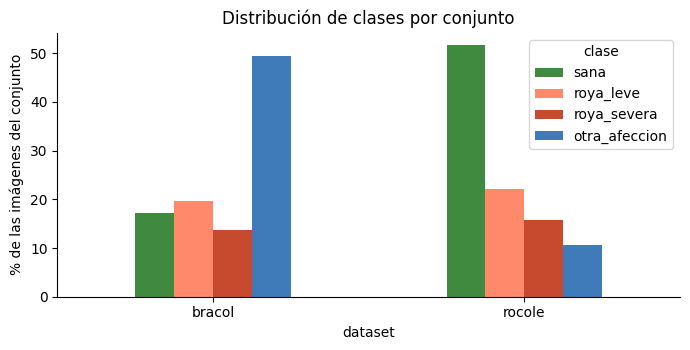

clase,sana,roya_leve,roya_severa,otra_afeccion
dataset,,,,
bracol,272,312,218,783
rocole,757,324,231,155


In [4]:
tab = pd.crosstab(U["dataset"], U["clase"])[list(CLASSES)]
ax = (tab.div(tab.sum(axis=1), axis=0) * 100).plot.bar(figsize=(7, 3.6), color=["#3F8A3E", "#FF8A6B", "#C84A2E", "#3F7BB8"], rot=0)
ax.set_ylabel("% de las imágenes del conjunto"); ax.set_title("Distribución de clases por conjunto"); plt.tight_layout(); plt.show()
display(tab)

**Lectura.** Los dos conjuntos tienen **distintas proporciones de clases** y no cubren las mismas: eso importa para el desbalance (por eso se usa
F1 macro y recall por clase) y para el cambio de dominio que aparece al entrenar con uno solo y probar en el otro.

## 3. Los dos conjuntos son dominios distintos
Tamaño de imagen y color medio sobre una muestra fija de cada conjunto.

,ancho_med,alto_med,R,G,B
dataset,,,,,
bracol,2048.0,1024.0,166.4,166.9,140.0
rocole,2048.0,1152.0,107.6,130.9,78.2


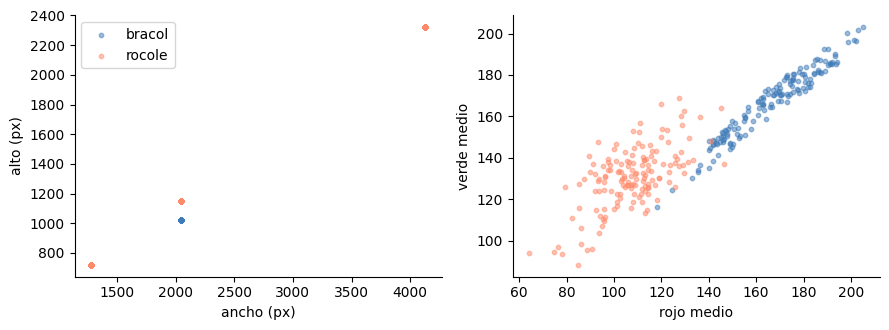

In [5]:
from PIL import Image
rng = np.random.default_rng(0)
rows = []
for ds, g in U.groupby("dataset"):
    for p in g["path"].sample(min(150, len(g)), random_state=0):
        with Image.open(p) as im:
            small = np.asarray(im.convert("RGB").resize((64, 64)), dtype=float)
            rows.append({"dataset": ds, "ancho": im.width, "alto": im.height, "R": small[..., 0].mean(), "G": small[..., 1].mean(), "B": small[..., 2].mean()})
D = pd.DataFrame(rows)
display(D.groupby("dataset").agg(ancho_med=("ancho", "median"), alto_med=("alto", "median"), R=("R", "mean"), G=("G", "mean"), B=("B", "mean")).round(1))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
for ds, c in zip(["bracol", "rocole"], ["#3F7BB8", "#FF8A6B"]):
    s = D[D["dataset"] == ds]
    ax[0].scatter(s["ancho"], s["alto"], s=10, alpha=0.5, label=ds, color=c); ax[1].scatter(s["R"], s["G"], s=10, alpha=0.5, label=ds, color=c)
ax[0].set_xlabel("ancho (px)"); ax[0].set_ylabel("alto (px)"); ax[1].set_xlabel("rojo medio"); ax[1].set_ylabel("verde medio"); ax[0].legend()
plt.tight_layout(); plt.show()

## 4. Ejemplos por clase y conjunto (muestra fija)

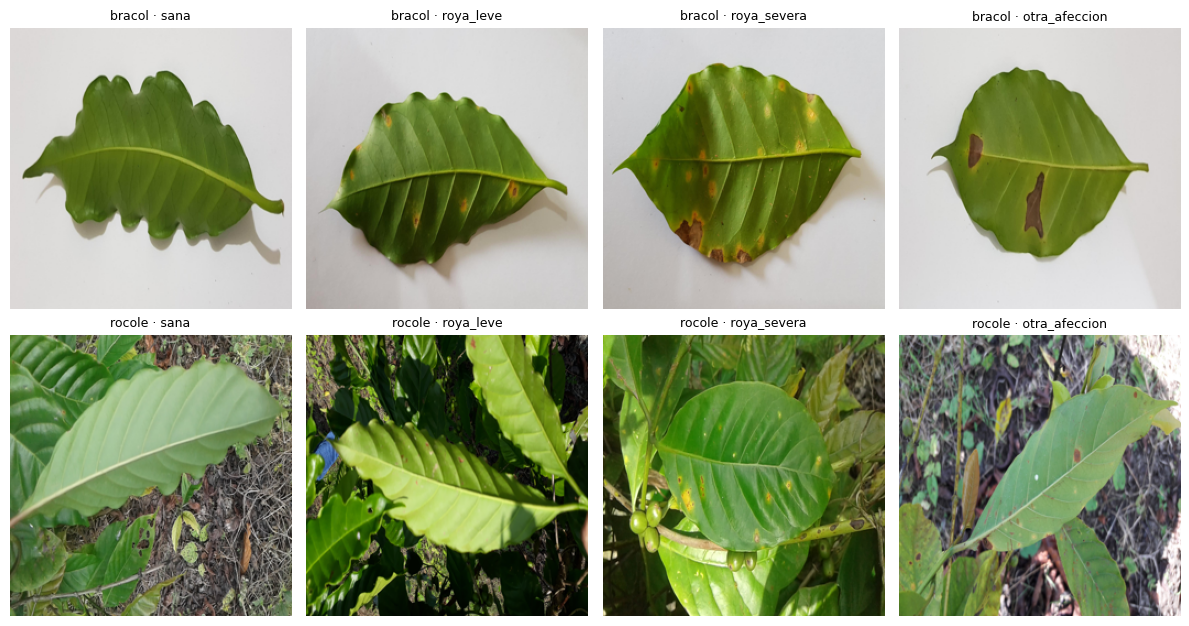

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6.4))
for r, ds in enumerate(["bracol", "rocole"]):
    for c, lab in enumerate(range(4)):
        ax = axes[r, c]; ax.axis("off")
        g = U[(U["dataset"] == ds) & (U["label"] == lab)]
        if len(g):
            with Image.open(g["path"].sample(1, random_state=3).iloc[0]) as im:
                ax.imshow(im.convert("RGB").resize((256, 256)))
        ax.set_title(f"{ds} · {NAMES[lab]}", fontsize=9)
plt.tight_layout(); plt.show()

## 5. El split no tiene fuga
Se comprueba directamente: ningún grupo (planta en RoCoLe, hoja en BRACOL) ni ningún hash exacto aparece en dos conjuntos.

In [7]:
split_per_group = S.groupby("group")["split"].nunique()
print("Grupos en más de un conjunto:", int((split_per_group > 1).sum()), "de", len(split_per_group))
hash_split = S.groupby("sha256")["split"].nunique()
print("Hashes exactos en más de un conjunto:", int((hash_split > 1).sum()))
display(pd.crosstab([S["dataset"], S["split"]], S["label"].map(NAMES))[list(CLASSES)])

Grupos en más de un conjunto: 0 de 1927
Hashes exactos en más de un conjunto: 0


label          sana  roya_leve  roya_severa  otra_afeccion
dataset split                                             
bracol  test     41         48           33            117
        train   190        217          153            548
        val      41         47           32            118
rocole  test    110         48           36             24
        train   536        227          160            108
        val     111         49           35             23

## 6. Conclusiones para el entrenamiento
- Hay desbalance y distintas proporciones por conjunto: se reportan F1 macro y recall por clase, no solo exactitud.
- Los dominios difieren en fondo, tamaño y color: un modelo entrenado con uno falla en el otro (ver `07_vision.ipynb`); se entrena con ambos y se evalúa por separado.
- El test de BRACOL (arábica) es la evaluación principal; las fotos de productores serán otro dominio, así que las cifras son una cota optimista.